# Autoregressive Word-Level Text Generation: SimpleRNN vs BiRNN vs LSTM vs GRU
**Author:** Varaang Tiwari (Reg. No. 230953378), School of Computer Engineering, Manipal Institute of Technology
**Course:** Foundations of Generative AI (ICT4403) - Assignment 2
**Dataset:** *Grimms' Fairy Tales* (Jacob & Wilhelm Grimm, English translation), Project Gutenberg #2591
**Source:** https://www.gutenberg.org/ebooks/2591

Run all cells top to bottom (Google Colab with GPU recommended). All four models share identical data, embedding size, optimiser, batch size, epoch budget and random seed so the comparison is fair.

In [12]:
import re, time, json, os, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42
tf.keras.utils.set_random_seed(SEED)
os.makedirs("results", exist_ok=True)

# ---- shared experimental configuration ----
SEQ_LEN    = 20      # context window (words)
VOCAB_SIZE = 5000    # most frequent words kept, the rest -> <OOV>
EMB_DIM    = 128
UNITS      = 256     # (BiRNN uses 128 per direction -> 256 output, so widths match)
BATCH      = 256
EPOCHS     = 20
LR         = 1e-3
DROPOUT    = 0.3
print(tf.__version__, tf.config.list_physical_devices("GPU"))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset: loading, characteristics and preprocessing

In [13]:
URL = "https://www.gutenberg.org/cache/epub/2591/pg2591.txt"
raw = urllib.request.urlopen(URL).read().decode("utf-8")

# strip Project Gutenberg licence header/footer
start = raw.find("*** START OF"); start = raw.find("\n", start) + 1
end   = raw.find("*** END OF")
raw = raw[start:end]

text = (raw.replace("\u2019", "'").replace("\u2018", "'")
           .replace("\u201c", '"').replace("\u201d", '"').replace("_", "").lower())
# tokens = words (with apostrophes) + basic punctuation as separate tokens
tokens = re.findall(r"[a-z']+|[.,!?;:]", text)

print(f"Characters: {len(raw):,} | Tokens: {len(tokens):,} | Unique tokens: {len(set(tokens)):,}")
from collections import Counter
print("Top 15:", Counter(tokens).most_common(15))

Characters: 530,055 | Tokens: 119,182 | Unique tokens: 5,193
Top 15: [(',', 8755), ('the', 6993), ('and', 5440), ('.', 3536), ('to', 2654), ("'", 2263), ('he', 2071), ('a', 1912), ('was', 1383), ('of', 1369), ('it', 1263), (';', 1261), ('she', 1210), ('said', 1161), ('in', 1153)]


**Dataset characteristics.** A collection of ~60 German folk tales in English (~100k words). It has a simple narrative voice, strongly repeated story formulas ("once upon a time", "the king said", "and they lived happily"), recurring characters (king, queen, fox, wolf, old woman) and heavy dialogue, which makes it suitable for word-level next-word prediction and small enough to train four models under identical conditions.

**Preprocessing:** remove Gutenberg boilerplate, normalise quotes, lowercase, remove underscores, tokenise into words and punctuation (`. , ! ? ; :`), keep the top 5,000 tokens and map the rest to `<OOV>`.

In [14]:
tok = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>", filters="", lower=False)
tok.fit_on_texts([tokens])
ids = np.array([tok.word_index.get(t, 1) if tok.word_index.get(t, 1) < VOCAB_SIZE else 1 for t in tokens], dtype=np.int32)
index_word = {i: w for w, i in tok.word_index.items() if i < VOCAB_SIZE}
print("Vocab used:", VOCAB_SIZE, "| OOV rate: %.2f%%" % (100 * (ids == 1).mean()))

# Chronological 80/10/10 split of the token stream BEFORE windowing (no window overlap/leakage between splits)
n = len(ids); a, b = int(.8 * n), int(.9 * n)
streams = {"train": ids[:a], "val": ids[a:b], "test": ids[b:]}

def make_xy(stream, L=SEQ_LEN):
    w = np.lib.stride_tricks.sliding_window_view(stream, L + 1)   # each row: L inputs + 1 target
    return w[:, :-1].copy(), w[:, -1].copy()

X_tr, y_tr = make_xy(streams["train"]); X_va, y_va = make_xy(streams["val"]); X_te, y_te = make_xy(streams["test"])
print("Train", X_tr.shape, "Val", X_va.shape, "Test", X_te.shape)
print("Example:", " ".join(index_word[i] for i in X_tr[0]), "->", index_word[y_tr[0]])

Vocab used: 5000 | OOV rate: 0.16%
Train (95325, 20) Val (11898, 20) Test (11899, 20)
Example: grimms' fairy tales by jacob grimm and wilhelm grimm preparer's note the text is based on translations from the grimms' -> kinder


**Input-target construction.** A sliding window (stride 1) of 20 words is the input; the word that follows is the target. Training maximises P(w_t | w_{t-20..t-1}), the autoregressive factorisation of the text.

## 2. Models (identical settings, only the recurrent layer changes)

In [15]:
def build(kind):
    inp = layers.Input(shape=(SEQ_LEN,))
    x = layers.Embedding(VOCAB_SIZE, EMB_DIM)(inp)
    if   kind == "SimpleRNN": x = layers.SimpleRNN(UNITS)(x)
    elif kind == "BiRNN":     x = layers.Bidirectional(layers.SimpleRNN(UNITS // 2))(x)
    elif kind == "LSTM":      x = layers.LSTM(UNITS)(x)
    elif kind == "GRU":       x = layers.GRU(UNITS)(x)
    x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(VOCAB_SIZE, activation="softmax")(x)
    m = models.Model(inp, out, name=kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(LR, clipnorm=1.0),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5")])
    return m

KINDS = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
trained, histories, train_time = {}, {}, {}
for k in KINDS:
    tf.keras.utils.set_random_seed(SEED)
    m = build(k)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS, batch_size=BATCH, callbacks=[es], verbose=2)
    train_time[k] = time.time() - t0
    trained[k], histories[k] = m, h.history
    print(f"== {k}: {m.count_params():,} params, {train_time[k]:.0f}s, {len(h.history['loss'])} epochs ==")

Epoch 1/20
373/373 - 10s - 26ms/step - accuracy: 0.0968 - loss: 5.9177 - top5: 0.2460 - val_accuracy: 0.1519 - val_loss: 5.3705 - val_top5: 0.3157
Epoch 2/20
373/373 - 2s - 7ms/step - accuracy: 0.1708 - loss: 5.0029 - top5: 0.3536 - val_accuracy: 0.1795 - val_loss: 4.9409 - val_top5: 0.3780
Epoch 3/20
373/373 - 2s - 6ms/step - accuracy: 0.1931 - loss: 4.5816 - top5: 0.4021 - val_accuracy: 0.1931 - val_loss: 4.8092 - val_top5: 0.3996
Epoch 4/20
373/373 - 2s - 6ms/step - accuracy: 0.2106 - loss: 4.3228 - top5: 0.4300 - val_accuracy: 0.1999 - val_loss: 4.7697 - val_top5: 0.4127
Epoch 5/20
373/373 - 2s - 6ms/step - accuracy: 0.2241 - loss: 4.1219 - top5: 0.4515 - val_accuracy: 0.2053 - val_loss: 4.7441 - val_top5: 0.4212
Epoch 6/20
373/373 - 2s - 6ms/step - accuracy: 0.2352 - loss: 3.9549 - top5: 0.4699 - val_accuracy: 0.2054 - val_loss: 4.7463 - val_top5: 0.4291
Epoch 7/20
373/373 - 2s - 6ms/step - accuracy: 0.2469 - loss: 3.8090 - top5: 0.4873 - val_accuracy: 0.2086 - val_loss: 4.7619 - 

## 3. Quantitative evaluation

In [16]:
rows = []
for k in KINDS:
    loss, acc, top5 = trained[k].evaluate(X_te, y_te, batch_size=512, verbose=0)
    rows.append({"Model": k, "Params": trained[k].count_params(), "Epochs run": len(histories[k]["loss"]),
                 "Train time (s)": round(train_time[k], 1), "Test loss": round(loss, 4),
                 "Perplexity": round(float(np.exp(loss)), 2), "Top-1 acc": round(acc, 4), "Top-5 acc": round(top5, 4)})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv("results/quantitative_results.csv")
results

,Params,Epochs run,Train time (s),Test loss,Perplexity,Top-1 acc,Top-5 acc
Model,,,,,,,
SimpleRNN,2023560,7,24.2,4.8588,128.87,0.1915,0.4141
BiRNN,1990792,8,30.7,4.9058,135.07,0.1946,0.4155
LSTM,2319240,11,53.0,4.8644,129.59,0.2004,0.4227
GRU,2221448,8,36.5,4.7365,114.03,0.2114,0.4309


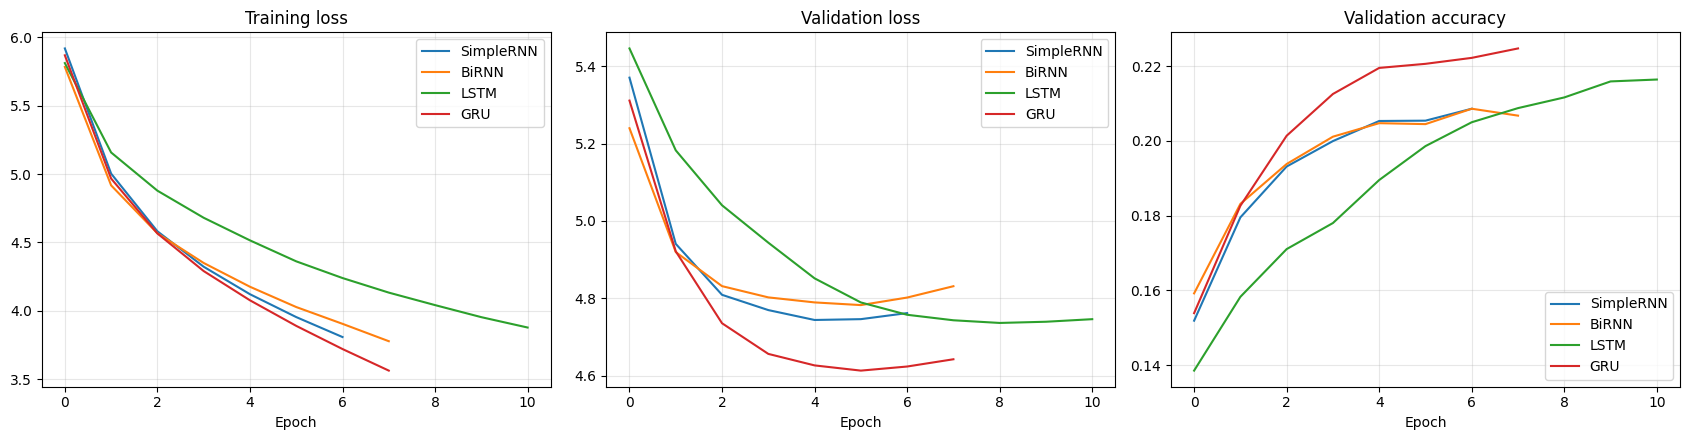

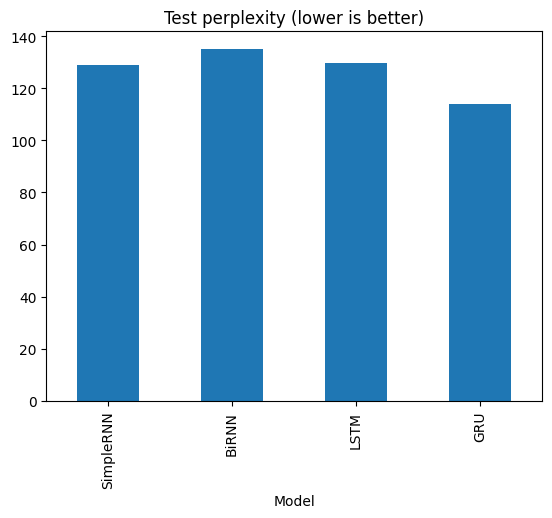

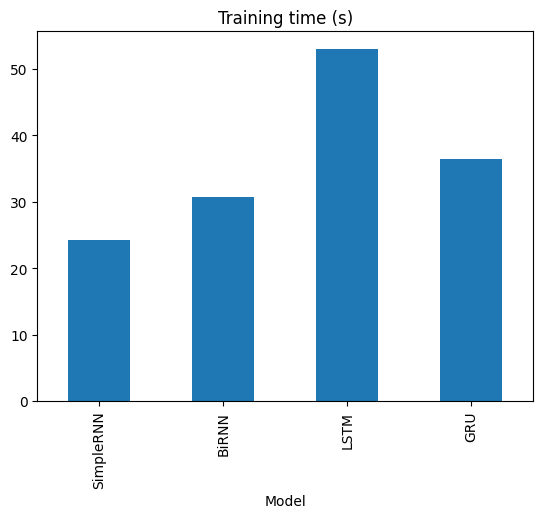

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k in KINDS:
    ax[0].plot(histories[k]["loss"], label=k);      ax[1].plot(histories[k]["val_loss"], label=k)
    ax[2].plot(histories[k]["val_accuracy"], label=k)
for a_, t in zip(ax, ["Training loss", "Validation loss", "Validation accuracy"]):
    a_.set_title(t); a_.set_xlabel("Epoch"); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=150); plt.show()

results[["Perplexity"]].plot.bar(legend=False, title="Test perplexity (lower is better)"); plt.savefig("results/perplexity.png", dpi=150); plt.show()
results[["Train time (s)"]].plot.bar(legend=False, title="Training time (s)"); plt.savefig("results/train_time.png", dpi=150); plt.show()

## 4. Autoregressive generation with temperature sampling

In [18]:
def sample(probs, temp):
    p = np.asarray(probs, dtype=np.float64).copy()
    p[0] = 0; p[1] = 0                       # never emit padding / <OOV>
    p = np.log(p + 1e-12) / temp
    p = np.exp(p - p.max()); p /= p.sum()
    return np.random.choice(len(p), p=p)

def detok(words):
    s = " ".join(words)
    return re.sub(r" ([.,!?;:])", r"\1", s)

def generate(model, seed_text, n_words=50, temp=1.0):
    seed = [tok.word_index.get(t, 1) for t in re.findall(r"[a-z']+|[.,!?;:]", seed_text.lower())]
    seed = ([0] * SEQ_LEN + seed)[-SEQ_LEN:]
    out = []
    for _ in range(n_words):
        p = model(np.array([seed]), training=False).numpy()[0]
        w = sample(p, temp)
        out.append(index_word.get(w, "<OOV>")); seed = seed[1:] + [w]
    return detok(out)

def text_metrics(text):
    w = text.split()
    d1 = len(set(w)) / len(w)
    bi = list(zip(w, w[1:])); tri = list(zip(w, w[1:], w[2:]))
    d2 = len(set(bi)) / max(len(bi), 1)
    rep3 = 1 - len(set(tri)) / max(len(tri), 1)    # fraction of repeated trigrams
    return d1, d2, rep3

SEEDS = ["once upon a time there lived a king who had three sons",
         "the poor little girl went into the forest and",
         "then the old woman said to the"]
TEMPS = [0.3, 0.7, 1.0, 1.3]
N_WORDS = 60

In [19]:
samples, mrows = [], []
for k in KINDS:
    for si, seed in enumerate(SEEDS):
        for T in TEMPS:
            np.random.seed(SEED + si)
            txt = generate(trained[k], seed, N_WORDS, T)
            d1, d2, r3 = text_metrics(txt)
            samples.append(f"### {k} | seed {si+1}: \"{seed}\" | T={T}\n{seed} **{txt}**\n")
            mrows.append({"Model": k, "Seed": si + 1, "Temp": T, "Distinct-1": d1, "Distinct-2": d2, "Repeated-3gram": r3})
open("results/generated_samples.md", "w").write("\n".join(samples))
gen = pd.DataFrame(mrows)
gen.to_csv("results/generation_metrics.csv", index=False)
summary = gen.groupby(["Model", "Temp"])[["Distinct-1", "Distinct-2", "Repeated-3gram"]].mean().round(3)
summary

Distinct-1  Distinct-2  Repeated-3gram
Model     Temp                                        
BiRNN     0.3        0.594       0.869           0.071
          0.7        0.740       0.981           0.000
          1.0        0.891       1.000           0.000
          1.3        0.926       0.994           0.000
GRU       0.3        0.643       0.894           0.027
          0.7        0.798       0.987           0.000
          1.0        0.839       1.000           0.000
          1.3        0.907       1.000           0.000
LSTM      0.3        0.628       0.876           0.020
          0.7        0.740       0.974           0.000
          1.0        0.843       1.000           0.000
          1.3        0.913       0.994           0.000
SimpleRNN 0.3        0.614       0.873           0.041
          0.7        0.760       0.986           0.000
          1.0        0.826       0.987           0.000
          1.3        0.918       1.000           0.000

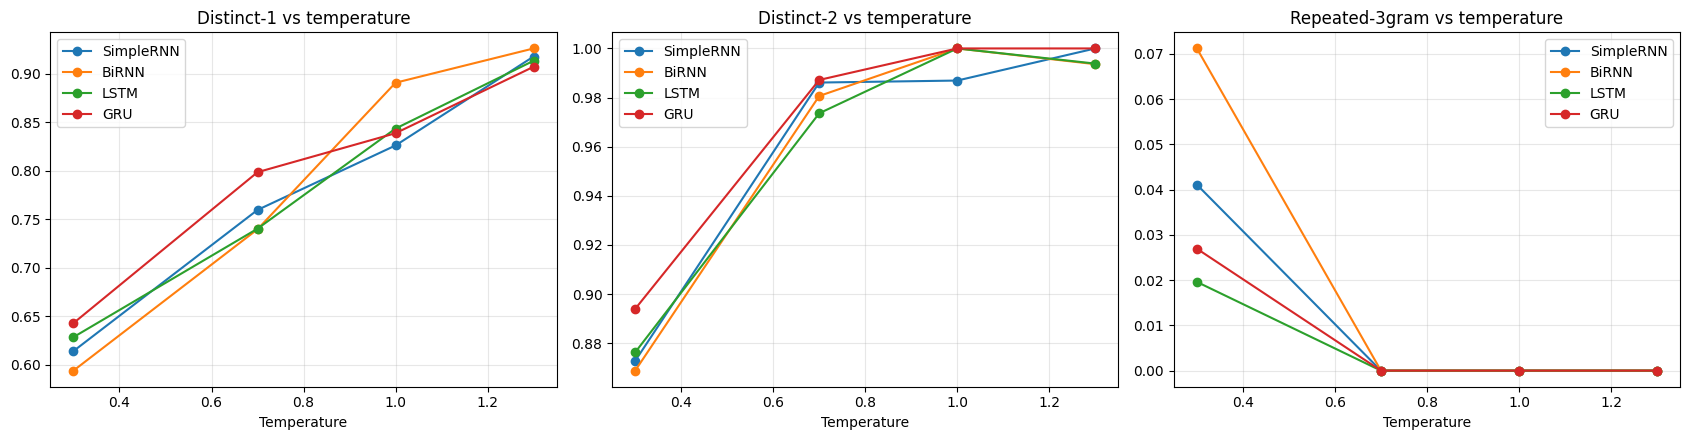

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for j, met in enumerate(["Distinct-1", "Distinct-2", "Repeated-3gram"]):
    for k in KINDS:
        s = gen[gen.Model == k].groupby("Temp")[met].mean(); ax[j].plot(s.index, s.values, marker="o", label=k)
    ax[j].set_title(met + " vs temperature"); ax[j].set_xlabel("Temperature"); ax[j].legend(); ax[j].grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/temperature_analysis.png", dpi=150); plt.show()

In [21]:
# Print one seed across all models and temperatures for qualitative reading
for k in KINDS:
    print("=" * 20, k, "=" * 20)
    for T in TEMPS:
        np.random.seed(SEED)
        print(f"[T={T}] {SEEDS[0]} {generate(trained[k], SEEDS[0], 50, T)}\n")

==================== SimpleRNN ====================
[T=0.3] once upon a time there lived a king who had three sons . ' then the king was a little daughter, and said: 'i will be a good way, and the world is a piece of bread, and i will not find him. ' the last said, 'i will give you to be a long of

[T=0.7] once upon a time there lived a king who had three sons . at last he had could it until he had. 'alas! ' said the door, 'i have soon. ' they went out, and then the huntsman was a favour in a tree, and said, 'i will try it? ' so he said

[T=1.0] once upon a time there lived a king who had three sons . 'dear pocket, ' said, thou big loved the cinders for it, and as my friend i am a poor thing; my father is once, but her will view someone sisters. ' 'what your father is the valiant son. ' at last the

[T=1.3] once upon a time there lived a king who had three sons so stabbed about: said, and trembling lying spoke the virtues its second upon the bread to cow. my can soon eat? there with me

## 5. Comparison and conclusion

In [22]:
best_ppl = results["Perplexity"].idxmin()
g07 = gen[gen.Temp == 0.7].groupby("Model")[["Distinct-2", "Repeated-3gram"]].mean()
print("Lowest perplexity:", best_ppl)
print("\nQuality at T=0.7 (higher Distinct-2 and lower Repeated-3gram are better):\n", g07.round(3))
print("\nFastest to train:", results["Train time (s)"].idxmin())

Lowest perplexity: GRU

Quality at T=0.7 (higher Distinct-2 and lower Repeated-3gram are better):
            Distinct-2  Repeated-3gram
Model                                
BiRNN           0.981             0.0
GRU             0.987             0.0
LSTM            0.974             0.0
SimpleRNN       0.986             0.0

Fastest to train: SimpleRNN


### Analysis (complete after running - replace with your observed numbers)
* **Quantitative:** Compare perplexity, top-1/top-5 accuracy and training time in the table above. Gated models (LSTM/GRU) are expected to reach lower validation loss than SimpleRNN because gates mitigate vanishing gradients over 20-step contexts; BiRNN reads the 20-word context in both directions, which can help prediction but is still a plain RNN.
* **Qualitative:** Read `results/generated_samples.md`. Judge *coherence* (grammatical, sensible phrases), *diversity* (Distinct-n), *contextual consistency* (stays on seed topic/characters) and *repetition* (Repeated-3gram, loops such as "the the the").
* **Temperature:** T=0.3 is near-greedy -> most grammatical but repetitive, loops likely; T=0.7 balances coherence and variety; T>=1.0 increases diversity but coherence drops and rare/odd words appear.
* **Best model:** state the model with the best trade-off of perplexity, text quality at T~0.7 and training cost, and justify it using your own results.